In [70]:
#| echo: false
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Validated categorical order (blue, orange, aqua, yellow); ink colors for text
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 130, "font.size": 11, "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False,
})
rng = np.random.default_rng(22)

# ---------- helpers (states are 0-indexed in code, 1-indexed in the slides) ----------
def stationary(P):
    """Solve balance eqs (one redundant equation dropped) + normalization."""
    m = P.shape[0]
    A = np.vstack([(P.T - np.eye(m))[:-1], np.ones(m)])
    rhs = np.zeros(m); rhs[-1] = 1
    return np.linalg.solve(A, rhs)

def simulate(P, x0, n, rng):
    cum = np.cumsum(P, axis=1); u = rng.random(n)
    x = np.empty(n + 1, dtype=int); x[0] = x0
    for t in range(n):
        x[t + 1] = min(np.searchsorted(cum[x[t]], u[t], side="right"), len(P) - 1)
    return x

def hitting_times(P, targets):
    """Mean time to reach the set `targets` (0 on targets): t_i = 1 + sum_j p_ij t_j."""
    n = len(P); T = [i for i in range(n) if i not in targets]
    Q = P[np.ix_(T, T)]; t = np.zeros(n)
    t[T] = np.linalg.solve(np.eye(len(T)) - Q, np.ones(len(T)))
    return t

def hitting_probs(P, s, absorbing):
    """Absorption probabilities a_i into absorbing state s."""
    n = len(P); T = [i for i in range(n) if i not in absorbing]
    Q = P[np.ix_(T, T)]; R = P[T, s]; a = np.zeros(n); a[s] = 1
    a[T] = np.linalg.solve(np.eye(len(T)) - Q, R)
    return a

def gamblers_P(m, p):
    P = np.zeros((m + 1, m + 1)); P[0, 0] = P[m, m] = 1
    for i in range(1, m):
        P[i, i + 1] = p; P[i, i - 1] = 1 - p
    return P

def ruin_closed(i, m, p):
    if np.isclose(p, 0.5): return i / m
    rho = (1 - p) / p
    return (1 - rho**i) / (1 - rho**m)

def duration_closed(i, m, p):
    if np.isclose(p, 0.5): return i * (m - i)
    rho = (1 - p) / p; d = (1 - p) - p
    return i / d - (m / d) * (1 - rho**i) / (1 - rho**m)

def node(ax, x, y, label, fc="white", ec=INK, r=0.32, fs=12):
    ax.add_patch(plt.Circle((x, y), r, fc=fc, ec=ec, lw=1.5, zorder=3))
    ax.text(x, y, label, ha="center", va="center", fontsize=fs, zorder=4)

def arrow(ax, a, b, rad=0.0, color=INK, lw=1.5):
    ax.annotate("", xy=b, xytext=a, zorder=2, arrowprops=dict(
        arrowstyle="-|>", color=color, lw=lw, shrinkA=0, shrinkB=0,
        connectionstyle=f"arc3,rad={rad}", mutation_scale=14))

def loop(ax, x, y, label, r=0.32, up=True, fs=11):
    s = 1 if up else -1
    ax.annotate("", xy=(x + 0.17, y + s * r * 0.93), xytext=(x - 0.17, y + s * r * 0.93), zorder=2,
                arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.5, connectionstyle=f"arc3,rad={-s*-1.9}",
                                mutation_scale=14, shrinkA=0, shrinkB=0))
    ax.text(x, y + s * (r + 0.55), label, ha="center", va="center", fontsize=fs)

# Steady-State Behavior

We are often interested in the long-term occupancy behavior in Markov models.  In particular, we'll be interested in the long-term behavior of the $n$-step transition probabilities
$$r_{ij}(n) \;=\; P(X_n = j \mid X_0 = i) \qquad \text{as } n \to \infty .$$

. . .

- After many steps, does the chain "settle down"?
- Does it matter **where we started** ($i$)?

. . .

We'll see that $r_{ij}(n) \to \pi_j \approx P(X_n = j),$ the *steady-state probability of $j$*.

## Motivating Example: Machine Working/Broken

Recall our example from the prior lecture: each day a machine is either **working** (state 1) or **broken** (state 2).

- If working today, it breaks down tomorrow with probability $b$.
- If broken today, it is repaired tomorrow with probability $r$.

$$P = \begin{bmatrix} 1-b & b \\ r & 1-r \end{bmatrix}$$

For numerical calculations in this example, we'll use $b = 0.1$ and $r = 0.5$.

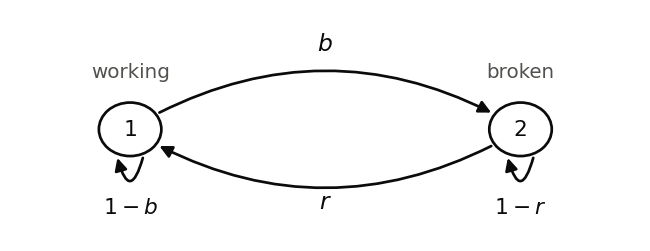

In [71]:
#| echo: false
fig, ax = plt.subplots(figsize=(6.2, 2.3)); ax.axis("off"); ax.set_xlim(-1.2, 5.2); ax.set_ylim(-1.3, 1.4); ax.grid(False)
node(ax, 0, 0, "1"); node(ax, 4, 0, "2")
ax.text(0, 0.62, "working", ha="center", color=MUTED); ax.text(4, 0.62, "broken", ha="center", color=MUTED)
arrow(ax, (0.3, 0.2), (3.7, 0.2), rad=-0.25); ax.text(2, 0.95, "$b$", ha="center", fontsize=13)
arrow(ax, (3.7, -0.2), (0.3, -0.2), rad=-0.25); ax.text(2, -0.95, "$r$", ha="center", fontsize=13)
for x_, lab in [(0, "$1-b$"), (4, "$1-r$")]:
    ax.annotate("", xy=(x_ - 0.14, -0.3), xytext=(x_ + 0.14, -0.3), zorder=2,
                arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.5, connectionstyle="arc3,rad=-1.9", mutation_scale=14))
    ax.text(x_, -1.0, lab, ha="center", fontsize=12)
plt.show()

## Example: Machine Working/Broken

Chapman–Kolmogorov: we can compute the the matrix with $i,j$th entry $r_{ij}(n)$ as the matrix power $P^n$.

In [72]:
#| echo: false
b, r = 0.1, 0.5
P = np.array([[1 - b, b],      # state 1: working
              [r, 1 - r]])     # state 2: broken

rows = []
for n in [1, 5, 10, 20]:
    R = np.linalg.matrix_power(P, n)
    rows.append({"n": n, "r11(n)": R[0, 0], "r12(n)": R[0, 1], "r21(n)": R[1, 0], "r22(n)": R[1, 1]})
print(pd.DataFrame(rows).round(4).to_string(index=False))

 n  r11(n)  r12(n)  r21(n)  r22(n)
 1  0.9000  0.1000  0.5000  0.5000
 5  0.8350  0.1650  0.8248  0.1752
10  0.8334  0.1666  0.8332  0.1668
20  0.8333  0.1667  0.8333  0.1667


. . .

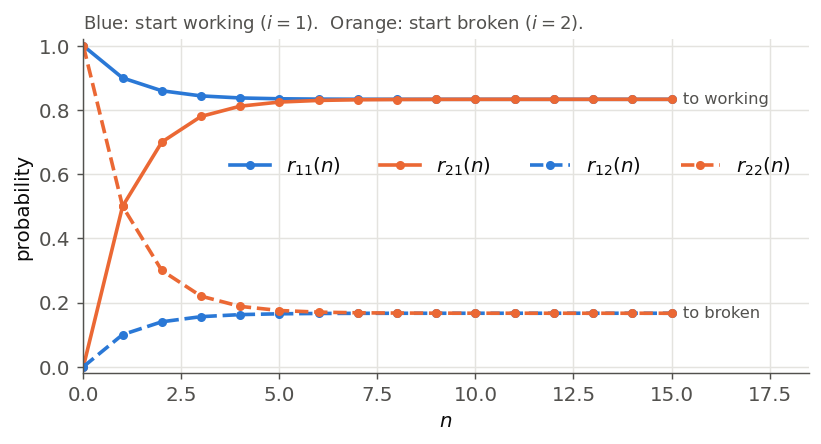

In [73]:
#| echo: false
ns = np.arange(0, 16)
R = np.array([np.linalg.matrix_power(P, n) for n in ns])
fig, ax = plt.subplots(figsize=(7.2, 3.4))
styles = [(0, 0, C[0], "-"), (1, 0, C[1], "-"), (0, 1, C[0], "--"), (1, 1, C[1], "--")]
for i, j, col, ls in styles:
    ax.plot(ns, R[:, i, j], color=col, ls=ls, marker="o", ms=4, label=f"$r_{{{i+1}{j+1}}}(n)$")
ax.set_xlabel("$n$"); ax.set_ylabel("probability"); ax.set_ylim(-0.02, 1.02)
ax.text(15.3, R[-1, 0, 0], "to working", color=MUTED, va="center", fontsize=9)
ax.text(15.3, R[-1, 0, 1], "to broken", color=MUTED, va="center", fontsize=9)
ax.set_xlim(0, 18.5); ax.legend(ncol=4, loc="center right", bbox_to_anchor=(1.0, 0.62))
ax.set_title("Blue: start working ($i=1$).  Orange: start broken ($i=2$).", loc="left", fontsize=10, color=MUTED)
plt.show()

## Steady-State Convergence

::: {.callout-note title="Theorem (Steady-state convergence)"}
Consider a Markov chain with a **single recurrent class** which is **aperiodic**. Then, the states $j$ are associated with **steady-state probabilities** $\pi_j$ that have the following properties.

1. For every state $j$, we have
$$\pi_j = \lim_{n \to \infty} r_{ij}(n)$$
for all $i$.

2. The $\pi_j$ are the unique solution of the **balance equations** and the **normalization equation**:
$$\pi_j = \sum_{k=1}^m \pi_k p_{kj}, \quad j = 1, \dots, m, \qquad\qquad \sum_{j=1}^m \pi_j = 1 .$$

3. $\pi_j = 0$ if $j$ is transient, and $\pi_j > 0$ if $j$ is recurrent.

:::

---

### Why each assumption is necessary

- *Single recurrent class.* If there are several recurrent classes, where the chain ends up depends on where it starts, so the limit **depends on $i$**.

- *Aperiodic.* If the recurrent class is periodic, the chain cycles deterministically through groups of states and $r_{ij}(n)$ **has no limit**.

## Stationary Distribution

::: {.callout-note title="Definition (Stationary distribution)"}
A probability distribution $\pi = (\pi_1, \dots, \pi_m)$ on the states is **stationary** if it satisfies the **balance equations**
$$\pi_j = \sum_{k=1}^m \pi_k \, p_{kj}, \qquad j = 1, \dots, m.$$
:::

. . .

**Why "stationary"?** If $P(X_0 = j) = \pi_j$ for all $j$, then
$$P(X_1 = j) = \sum_k P(X_0 = k)\, p_{kj} = \sum_k \pi_k p_{kj} = \pi_j ,$$
and by induction $X_n \sim \pi$ for **every** $n$: the distribution no longer changes.

## Stationary Distribution

**Balance equations:**

Recall the Chapman–Kolmogorov equation:
$$r_{ij}(n) = \sum_{k=1}^m r_{ik}(n-1)\, p_{kj} .$$

. . .

Let $n \to \infty$. Under the assumptions of the theorem, $r_{ij}(n) \to \pi_j$ and $r_{ik}(n-1) \to \pi_k$, and the sum is **finite**, so the limit passes through it:
$$\pi_j = \sum_{k=1}^m \pi_k \, p_{kj} . \qquad\blacksquare$$

. . .

The steady-state probabilities satisfy $\pi = \pi \mathbf{P}$, i.e. $\pi$ is a left eigenvector of $\mathbf{P}$ with eigenvalue $1$. A very famous theorem, the Perron-Frobenius theorem in linear algebra guarantees that such a vector will exist for any transition probability matrix $\mathbf{P}$ whose Markov chain satisfies the assumptions in the prior theorem.

### Example: Machine Working/Broken

Balance equations (with $\pi_1$ = working, $\pi_2$ = broken):
$$\pi_1 = (1-b)\,\pi_1 + r\,\pi_2 , \qquad \pi_2 = b\,\pi_1 + (1-r)\,\pi_2 .$$

. . .

Both reduce to the **same** equation $b\,\pi_1 = r\,\pi_2$. Use normalization $\pi_1 + \pi_2 = 1:$
$$\pi_1 = \frac{r}{b + r}, \qquad \pi_2 = \frac{b}{b + r} .$$

. . .

With $b = 0.1$, $r = 0.5$: $\;\pi = \left(\tfrac56, \tfrac16\right) \approx (0.8333,\, 0.1667)$.

---

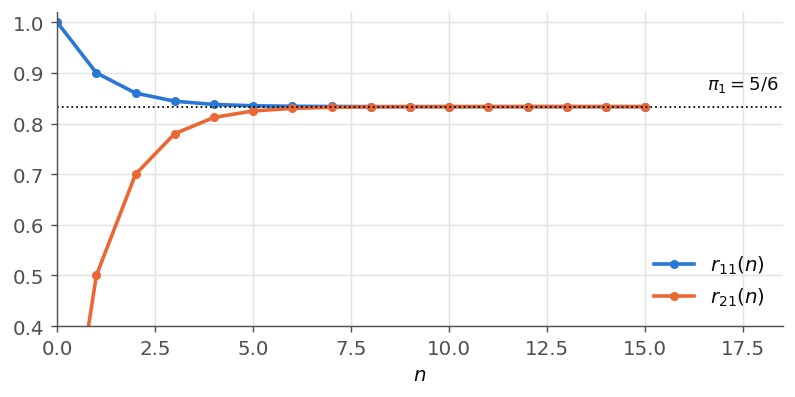

In [74]:
#| echo: false
ns = np.arange(0, 16)
R = np.array([np.linalg.matrix_power(P, n) for n in ns])

# stationary distribution: left eigenvector of P for eigenvalue 1, normalized to sum to 1
w, v = np.linalg.eig(P.T)
pi = np.real(v[:, np.argmin(np.abs(w - 1))])
pi = pi / pi.sum()

fig, ax = plt.subplots(figsize=(7.2, 3.2))
ax.plot(ns, R[:, 0, 0], color=C[0], marker="o", ms=4, label="$r_{11}(n)$")
ax.plot(ns, R[:, 1, 0], color=C[1], marker="o", ms=4, label="$r_{21}(n)$")
ax.axhline(pi[0], color=INK, lw=1, ls=":"); ax.text(18.4, pi[0] + 0.025, r"$\pi_1 = 5/6$", va="bottom", ha="right", fontsize=10)
ax.set_xlabel("$n$"); ax.set_xlim(0, 18.5); ax.set_ylim(0.4, 1.02); ax.legend(loc="lower right")
plt.show()

## Long-Term Frequency Interpretation

Let $v_{ij}(n)$ be the expected number of visits to $j$ in the first $n$ transitions, starting from $i$:
$$v_{ij}(n) = E\big[|\{k \le n : X_k = j\}| \mid X_0 = i\big] = \sum_{k=1}^n r_{ij}(k).$$

. . .

If $r_{ij}(k) \to \pi_j$, then the *average* of the first $n$ terms converges to the same limit:
$$\frac{v_{ij}(n)}{n} \;\longrightarrow\; \pi_j \qquad (n \to \infty).$$

**$\pi_j$ is the long-run expected fraction of time the chain spends in state $j$**, whatever the starting state. 

---

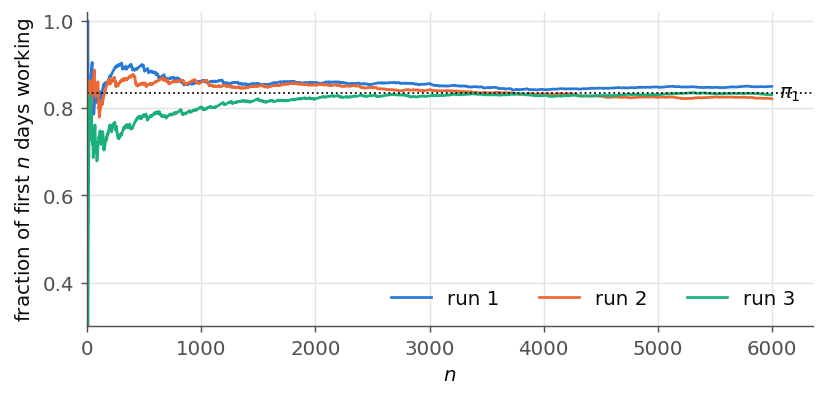

In [75]:
#| echo: false
n_steps = 6000
fig, ax = plt.subplots(figsize=(7.2, 3.2))
for k, col in zip(range(3), C):
    x = simulate(P, 1, n_steps, rng)                    # start broken
    frac = np.cumsum(x[1:] == 0) / np.arange(1, n_steps + 1)
    ax.plot(np.arange(1, n_steps + 1), frac, color=col, lw=1.5, label=f"run {k+1}")
ax.axhline(pi[0], color=INK, lw=1, ls=":"); ax.text(n_steps * 1.01, pi[0], r"$\pi_1$", va="center")
ax.set_xlabel("$n$"); ax.set_ylabel("fraction of first $n$ days working"); ax.set_ylim(0.3, 1.02)
ax.set_xlim(0, n_steps * 1.06); ax.legend(ncol=3, loc="lower right")
plt.show()

### Balance equations

If $\pi_j$ is the fraction of time at $j$, then the number of visits to $j$ is the **sum of the numbers of visits to neighbors that transition to $j$**: each visit to $k$ is followed by a jump to $j$ with probability $p_{kj}$. So transitions $k \to j$ occur with frequency $\pi_k\, p_{kj}$, and
$$\boxed{\;\pi_j = \sum_{k} \pi_k\, p_{kj}\;}$$

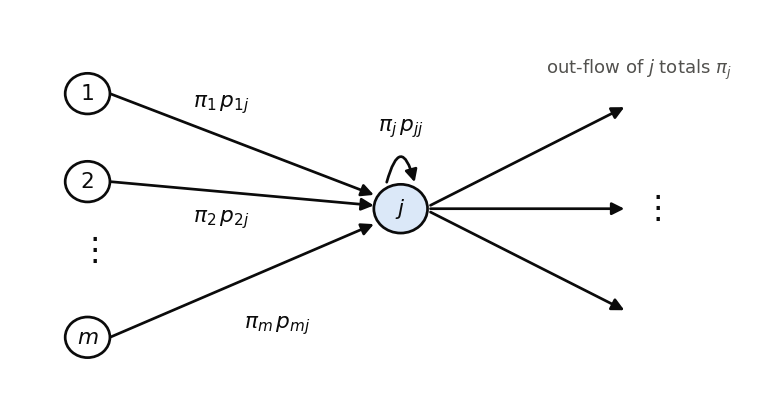

In [76]:
#| echo: false
fig, ax = plt.subplots(figsize=(7.4, 4.0)); ax.axis("off"); ax.grid(False)
ax.set_xlim(-1, 9); ax.set_ylim(-1.2, 4.6)
J = (4.2, 1.7)
ins = [(0, 3.4, "1"), (0, 2.1, "2"), (0, -0.2, "$m$")]
offs = {"1": (0.15, 0.42), "2": (0.15, -0.42), "m": (0.9, -0.45)}
for (x, y, lab), k in zip(ins, ["1", "2", "m"]):
    node(ax, x, y, lab, r=0.3)
    end = (J[0] - 0.36, J[1] + (y - J[1]) * 0.12)
    arrow(ax, (x + 0.3, y), end, rad=0.0)
    t = 0.38; px = x + 0.3 + t * (end[0] - x - 0.3); py = y + t * (end[1] - y)
    ax.text(px + offs[k][0], py + offs[k][1], rf"$\pi_{{{k}}}\,p_{{{k}j}}$", fontsize=12, ha="center", va="center")
ax.text(0, 0.95, r"$\vdots$", fontsize=18, ha="center")
node(ax, *J, "$j$", fc="#dbe8f8", r=0.36)
ax.annotate("", xy=(J[0] + 0.2, J[1] + 0.34), xytext=(J[0] - 0.2, J[1] + 0.34),
            arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.5, connectionstyle="arc3,rad=-1.9", mutation_scale=14))
ax.text(J[0], J[1] + 1.15, r"$\pi_j\,p_{jj}$", fontsize=12, ha="center")
for dy in [1.5, 0, -1.5]:
    arrow(ax, (J[0] + 0.4, J[1] + 0.05 * np.sign(dy)), (J[0] + 3.0, J[1] + dy), rad=0.0)
ax.text(J[0] + 3.35, J[1] + 0.0, r"$\vdots$", fontsize=18, ha="center", va="center", rotation=0)
ax.text(J[0] + 3.2, J[1] + 2.0, "out-flow of $j$ totals $\\pi_j$", fontsize=10, color=MUTED, ha="center")
plt.show()

# Absorption

**Definition.** A state $s$ is **absorbing** if $p_{ss} = 1$: once the chain enters $s$ it never leaves. An absorbing state is a recurrent class by itself.

. . .

Recall the classification of Markov chain behavior:

- The chain visits each of the transient states at most a finite number of times initially.
- With probability $1$, the chain eventually leaves the transient states **for good** and enters a recurrent class, where it remains **forever** and visits its states **infinitely often**.
- This is **absorption**.

. . .

Two natural questions: **which** recurrent class (absorbing state) does it end up in, and **how long** does it take?

## Absorption Probability Equations

Fix an absorbing state $s$. Define the **absorption probability**
$$a_i = P(X_n \text{ eventually equals } s \mid X_0 = i) .$$

. . .

::: {.callout-note title="Absorption probability equations"}
Consider a Markov chain where each state is either transient or absorbing, and fix a particular absorbing state $s$.  Then the probabilities $a_i$ of eventually reaching state $s$, starting from $i$, are the unique solution to the equations
$$a_s = 1, \\a_i = 0 \;\text{ for every absorbing } i \ne s, \\a_i = \sum_{j=1}^m p_{ij}\, a_j \;\text{ for every transient } i .$$
:::

. . .

This system has a **unique solution**.

### Example: Gambler's Ruin

A gambler starts with $\$i$ and plays rounds, winning $\$1$ with probability $p$ and losing $\$1$ with probability $q = 1-p$, independently. She stops when she reaches $\$m$ (target) or $\$0$ (ruin).

**Question:** what is the probability she reaches $\$m$ before going broke?

. . .

This is a Markov chain on $\{0, 1, \dots, m\}$ with $p_{i,i+1} = p$, $\;p_{i,i-1} = q$ for $0 < i < m$, and $p_{00} = p_{mm} = 1$.

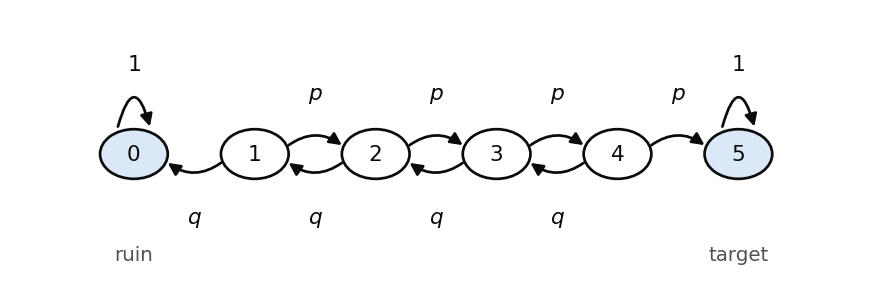

In [77]:
#| echo: false
m_demo = 5
fig, ax = plt.subplots(figsize=(8.4, 2.8)); ax.axis("off"); ax.grid(False)
ax.set_xlim(-1.0, m_demo + 1.0); ax.set_ylim(-1.5, 1.6)
for i in range(m_demo + 1):
    absorb = i in (0, m_demo)
    node(ax, i, 0, str(i), fc="#dbe8f8" if absorb else "white", r=0.28)
for i in range(1, m_demo):          # transient states: right w.p. p, left w.p. q
    arrow(ax, (i + 0.28, 0.1), (i + 1 - 0.28, 0.1), rad=-0.35)
    ax.text(i + 0.5, 0.62, "$p$", ha="center", fontsize=12)
    arrow(ax, (i - 0.28, -0.1), (i - 1 + 0.28, -0.1), rad=-0.35)
    ax.text(i - 0.5, -0.78, "$q$", ha="center", fontsize=12)
for x in (0, m_demo):
    ax.annotate("", xy=(x + 0.14, 0.27), xytext=(x - 0.14, 0.27),
                arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.5, connectionstyle="arc3,rad=-1.9", mutation_scale=14))
    ax.text(x, 0.95, "$1$", ha="center", fontsize=12)
ax.text(0, -1.2, "ruin", ha="center", color=MUTED); ax.text(m_demo, -1.2, "target", ha="center", color=MUTED)
plt.show()

---

**Transient and recurrent states**

- States $0$ and $m$ are **absorbing**, so each is a **recurrent class** by itself.
- States $1, \dots, m-1$ are **transient**: from each, there is a positive probability of reaching $0$ or $m$ (which can never come back).
- There are finitely many transient states, so the gambler is **absorbed** with probability $1$: she either reaches the target or goes broke (the game ends).

. . .

Fix $s = m$ and let $a_i$ be the probability that the gambler reaches $m$ beginning from state $i$.

---

**Calculate the absorption probabilities** (absorbing state $s = m$)

$$a_0 = 0, \qquad a_m = 1, \qquad a_i = p\,a_{i+1} + q\,a_{i-1}, \quad 0 < i < m.$$

. . .

Write $a_i = (p+q)\,a_i$ and rearrange:
$$a_{i+1} - a_i = \rho\,(a_i - a_{i-1}), \qquad \rho = \frac{q}{p}.$$

. . .

Since $a_0 = 0$: $\;a_{i+1} - a_i = \rho^{i}\, a_1$. Summing,
$$a_i = a_1\,(1 + \rho + \dots + \rho^{i-1}).$$

. . .

Use $a_m = 1$ to find $a_1 = 1/(1 + \rho + \dots + \rho^{m-1})$.

---

$$\boxed{\; a_i = \begin{cases} \dfrac{1 - \rho^{\,i}}{1 - \rho^{\,m}}, & p \ne \tfrac12 \quad (\rho = q/p),\\[3mm] \dfrac{i}{m}, & p = \tfrac12 . \end{cases}}$$

Check: $a_0 = 0$ and $a_m = 1$.

---

**The dependence on $p$ and $m$:**

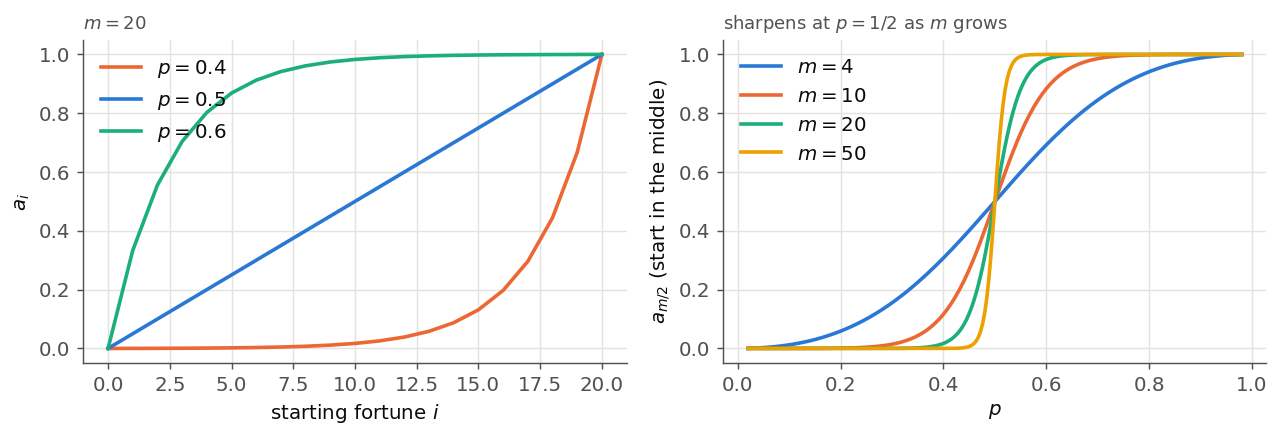

In [78]:
#| echo: false
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
m = 20; ii = np.arange(0, m + 1)
for p_, col in zip([0.4, 0.5, 0.6], [C[1], C[0], C[2]]):
    axs[0].plot(ii, [ruin_closed(i, m, p_) for i in ii], color=col, label=f"$p={p_}$")
axs[0].set_xlabel("starting fortune $i$"); axs[0].set_ylabel("$a_i$"); axs[0].set_title("$m=20$", loc="left", fontsize=10, color=MUTED)
axs[0].legend(loc="upper left")
ps = np.linspace(0.02, 0.98, 241)
for m_, col in zip([4, 10, 20, 50], C):
    axs[1].plot(ps, [ruin_closed(m_ // 2, m_, q_) for q_ in ps], color=col, label=f"$m={m_}$")
axs[1].set_xlabel("$p$"); axs[1].set_ylabel(r"$a_{m/2}$ (start in the middle)")
axs[1].set_title("sharpens at $p = 1/2$ as $m$ grows", loc="left", fontsize=10, color=MUTED)
axs[1].legend(loc="upper left")
plt.tight_layout(); plt.show()

## Expected Time to Absorption

**Definition.** Starting from state $i$, let
$$\mu_i = E[\text{number of transitions until absorption starting from } i] \\= E[\min\{n \ge 0 \mid X_n \text{ is recurrent}\} \mid X_0 = i].$$

. . .

::: {.callout-note title="Equations for the expected time to absorption"}
The expected times to absorption, $\mu_1, \cdots, \mu_m$, are the unique solution to the equations
$$\mu_i = 0 \;\text{ for every recurrent } i, \\ \mu_i = 1 + \sum_{j=1}^m p_{ij}\,\mu_j \;\text{ for every transient } i .$$
:::

. . .

*Why?* One transition is used (the "$1$") to leave $i$, then the chain is at $j$ with probability $p_{ij}$ and needs $\mu_j$ more transitions on average.

### Example: Gambler's Ruin

**Mean absorption: expected duration of the gambler's game.** Same chain ($p = 0.45$, $m = 10$, start $i = 5$):
$$\mu_0 = \mu_m = 0, \qquad \mu_i = 1 + p\,\mu_{i+1} + q\,\mu_{i-1}.$$

In [79]:
p, m, i0 = 0.45, 10, 5
mu = hitting_times(gamblers_P(m, p), targets={0, m})
#print("linear system mu_5 :", round(mu[i0], 3))
#print("closed form  mu_5 :", round(duration_closed(i0, m, p), 3))
#print("fair game closed form i(m-i) at i=5:", duration_closed(5, 10, 0.5))

N = 200_000
pos = np.full(N, i0); steps = np.zeros(N, dtype=int); active = np.ones(N, dtype=bool)
while active.any():
    move = np.where(rng.random(N) < p, 1, -1)
    pos[active] += move[active]; steps[active] += 1
    active = (pos > 0) & (pos < m)
#print("simulation mean    :", round(steps.mean(), 3))

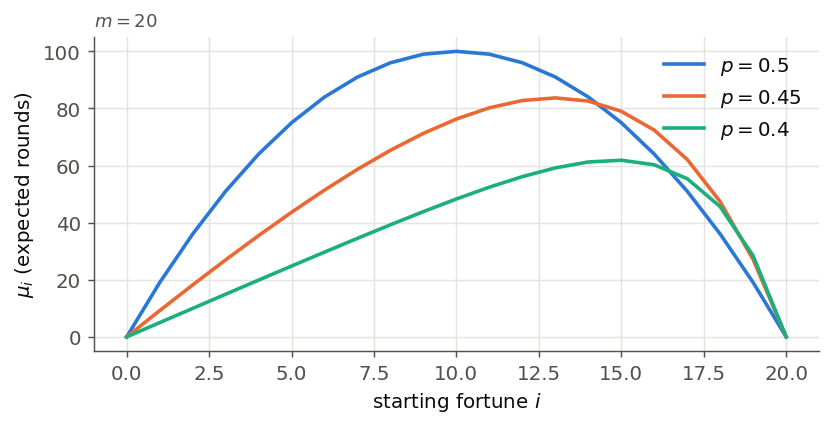

In [80]:
#| echo: false
fig, ax = plt.subplots(figsize=(7.2, 3.2))
m = 20; ii = np.arange(0, m + 1)
for p_, col in zip([0.5, 0.45, 0.4], C):
    ax.plot(ii, [duration_closed(i, m, p_) for i in ii], color=col, label=f"$p={p_}$")
ax.set_xlabel("starting fortune $i$"); ax.set_ylabel(r"$\mu_i$ (expected rounds)")
ax.set_title("$m=20$", loc="left", fontsize=10, color=MUTED); ax.legend(loc="upper right")
plt.show()

# Mean Passage + Recurrence

For simplicity we now consider a chain with a **single recurrent class** and fix a recurrent state $s$.

**Mean first passage time** to $s$ from $i$:
$$t_i = E\big[\min\{n \ge 0 : X_n = s\} \mid X_0 = i\big] .$$

. . .

**Mean recurrence time** of $s$:
$$t_s^* = E\big[\min\{n \ge 1 : X_n = s\} \mid X_0 = s\big] .$$


# Mean Passage + Recurrence

::: {.callout-note title="Equations for mean first passage and recurrence times"}
The mean first passage time values satisfy
$$t_s = 0, \qquad t_i = 1 + \sum_{j=1}^m p_{ij}\, t_j \;\;\text{ for } i \ne s ,$$
and the mean recurrence time is related to the first passage times as
$$t_s^* = 1 + \sum_{j=1}^m p_{sj}\, t_j .$$
:::

### Example: broken/working machine

Mean first passage time: 

Target state $s = 1$ (working). From broken (state 2):
$$t_2 = 1 + (1 - r)\,t_2 + r\,t_1 \;\Longrightarrow\; t_2 = \frac1r.$$

. . .

 This is the expectation of a geometric RV!

. . .

Mean recurrence time of "working":
$$t_1^* = 1 + (1-b)\,t_1 + b\,t_2 = 1 + \frac{b}{r} = \frac{b + r}{r} = \frac{1}{\pi_1}.$$